In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#Dataset loading
data = pd.read_csv('dirty_data1.csv')
data.head()

,Car Colour,Date,Occupants,Make,Model
0,Red,2023-03-15,2,Ford,Focus
1,rEd,15/03/2023,three,Toyta,Corolla
2,NaN,"March 15, 2023",4,Volkswagen,Golf
3,rd,2023/03/15,2,cyclist,NaN
4,Blue,2023-03-16,one,Honda,Civic


#### Заметим, что данные представлены в разрозненном виде и требуют чистки

In [3]:
#Проверяем пропуски
data.info()
data.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 136 entries, 0 to 135
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Car Colour  112 non-null    object
 1   Date        136 non-null    object
 2   Occupants   124 non-null    object
 3   Make        135 non-null    object
 4   Model       111 non-null    object
dtypes: object(5)
memory usage: 5.4+ KB


Car Colour    24
Date           0
Occupants     12
Make           1
Model         25
dtype: int64

In [4]:
#Заменяем пропуски в категориальных колонках на "unknow", ряды с неизвестными Occupants придётся удалить
for col in['Car Colour','Make','Model']:
    data[col] = data[col].fillna('unknown')
data = data.dropna(subset = 'Occupants')

In [5]:
data.info()
data.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
Index: 124 entries, 0 to 135
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Car Colour  124 non-null    object
 1   Date        124 non-null    object
 2   Occupants   124 non-null    object
 3   Make        124 non-null    object
 4   Model       124 non-null    object
dtypes: object(5)
memory usage: 5.8+ KB


Car Colour    0
Date          0
Occupants     0
Make          0
Model         0
dtype: int64

#### Пропуски в данных были устранены, преступаем к преодбработке данных

In [6]:
#Очистим данные, приведя их к единому виду и удалим строки, содержащие не машины
data['Car Colour'].unique()

array(['Red', 'rEd', 'unknown', 'rd', 'Blue', 'blu', 'Green', 'grn',
       'March 20, 2023', 'yellow', 'ylw', 'Yellow', 'yel', 'YELLOW',
       'red'], dtype=object)

In [7]:
#Исправляем цвета
mapping = {'rEd':'Red','rd':'Red','red':'Red','blu':'Blue','grn':'Green','ylw':'Yellow','yel':'Yellow','YELLOW':'Yellow','yellow':'Yellow'}
data['Car Colour'] = data['Car Colour'].str.strip().str.lower().map(mapping).fillna(data['Car Colour'])
delete_color = ['March 20, 2023']
data = data[~data['Car Colour'].isin(delete_color)]

In [8]:
data['Car Colour'].unique()

array(['Red', 'unknown', 'Blue', 'Green', 'Yellow'], dtype=object)

In [9]:
#Стандартизируем формат даты
data['Date'] = pd.to_datetime(data['Date'], errors = 'coerce', dayfirst = True)

C:\Users\ohelg\AppData\Local\Temp\ipykernel_20768\2488597795.py:2: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  data['Date'] = pd.to_datetime(data['Date'], errors = 'coerce', dayfirst = True)


In [10]:
data['Date']

0     2023-03-15
1            NaT
2            NaT
3            NaT
4     2023-03-16
         ...    
130          NaT
131   2023-05-01
133          NaT
134   2023-05-02
135          NaT
Name: Date, Length: 123, dtype: datetime64[ns]

In [11]:
#Проведём чистку колонки с пассажирами
data['Occupants'].unique()
#Переведём всё в числовой формат

array(['2', 'three', '4', 'one', '1', 'two'], dtype=object)

In [12]:
map_occupant = {'one':1,'two':2,'three':3,'four':4}
def numeric_occupants(x):
    if pd.isnull(x):return np.nan
    x = str(x).strip().lower()
    return map_occupant.get(x, pd.to_numeric(x, errors = 'coerce'))
data['Occupants'] = data['Occupants'].apply(numeric_occupants)
data['Occupants'].unique()

array([2, 3, 4, 1])

In [13]:
#Теперь нужно убрать все записи с не машинами
data['Make'].unique()

array(['Ford', 'Toyta', 'Volkswagen', 'cyclist', 'Honda', 'Hyundai',
       'Motorbike', 'Peugeot', 'Renault', 'Skoda'], dtype=object)

In [14]:
data['Model'].unique()

array(['Focus', 'Corolla', 'Golf', 'unknown', 'Civic', 'Elantra', '208',
       'Clio', 'Fiesta', 'Passat', 'i30', '308', 'Megane', 'Octavia'],
      dtype=object)

In [15]:
not_cars = ['cyclist','motorbike']
data = data[~data['Make'].str.lower().isin(not_cars)]

In [16]:
data

,Car Colour,Date,Occupants,Make,Model
0,Red,2023-03-15,2,Ford,Focus
1,Red,NaT,3,Toyta,Corolla
2,unknown,NaT,4,Volkswagen,Golf
4,Blue,2023-03-16,1,Honda,Civic
5,Blue,NaT,1,Hyundai,Elantra
...,...,...,...,...,...
128,unknown,2023-04-30,4,Volkswagen,Golf
130,Blue,NaT,1,Honda,Civic
131,Blue,2023-05-01,1,Hyundai,Elantra
134,Green,2023-05-02,2,Peugeot,208


### Предобработка данных завершена, попробуем добавить столбец, показывающий машины у которых 2 и более мест в салоне

In [17]:
data['Two or more occupants'] = data['Occupants']>2
data

,Car Colour,Date,Occupants,Make,Model,Two or more occupants
0,Red,2023-03-15,2,Ford,Focus,False
1,Red,NaT,3,Toyta,Corolla,True
2,unknown,NaT,4,Volkswagen,Golf,True
4,Blue,2023-03-16,1,Honda,Civic,False
5,Blue,NaT,1,Hyundai,Elantra,False
...,...,...,...,...,...,...
128,unknown,2023-04-30,4,Volkswagen,Golf,True
130,Blue,NaT,1,Honda,Civic,False
131,Blue,2023-05-01,1,Hyundai,Elantra,False
134,Green,2023-05-02,2,Peugeot,208,False


## Проведём визуализацию данных

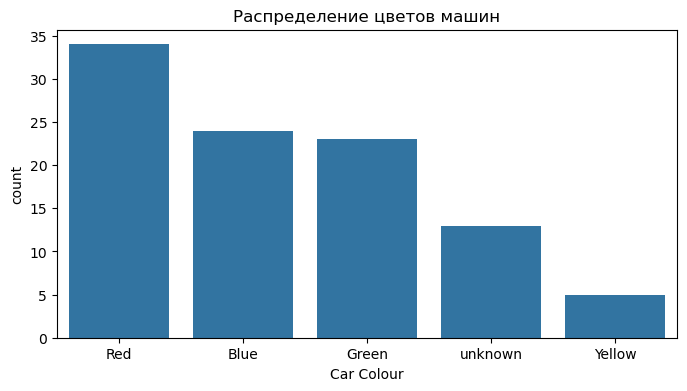

In [18]:
#Распределение цветов
plt.figure(figsize=(8,4))
sns.countplot(data = data, x = 'Car Colour',order = data['Car Colour'].value_counts().index)
plt.title('Распределение цветов машин')
plt.show()

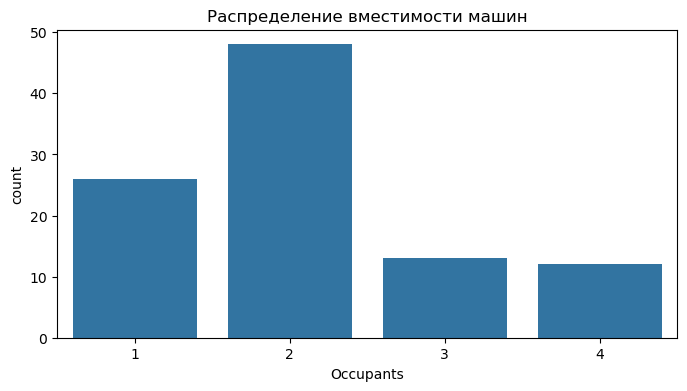

In [21]:
#Распределение вместимости машин
plt.figure(figsize=(8,4))
sns.countplot(data = data, x = 'Occupants')
plt.title('Распределение вместимости машин')
plt.show()

## Добавим ещё данных для выявление более полноценной статистики

In [43]:
a = pd.read_csv('dirty_data1.csv')
b = pd.read_csv('dirty_data2.csv')
c = pd.read_csv('dirty_data3.csv')
#Добавим в данные столбцы, показывающие к какому файлу они принадлежат для чистоты анализа данных
a['Group'] = 'alpha'
b['Group'] = 'beta'
c['Group'] = 'gamma'
full_data = pd.concat([a,b,c], ignore_index = True)
full_data.head()

,Car Colour,Date,Occupants,Make,Model,Group
0,Red,2023-03-15,2,Ford,Focus,alpha
1,rEd,15/03/2023,three,Toyta,Corolla,alpha
2,NaN,"March 15, 2023",4,Volkswagen,Golf,alpha
3,rd,2023/03/15,2,cyclist,NaN,alpha
4,Blue,2023-03-16,one,Honda,Civic,alpha


In [44]:
#Приведём столбец с местами к числовому типу, использую функцию созданную ранее
full_data['Occupants'] = full_data['Occupants'].apply(numeric_occupants)
full_data = full_data.dropna(subset = ['Occupants'])
full_data['Occupants'].unique()

array([2., 3., 4., 1.])

In [45]:
#Переходим к чистке столбца с цветами
full_data = full_data.fillna('unknown')

full_data['Car Colour'] = full_data['Car Colour'].str.strip().str.upper()
full_data

,Car Colour,Date,Occupants,Make,Model,Group
0,RED,2023-03-15,2.0,Ford,Focus,alpha
1,RED,15/03/2023,3.0,Toyta,Corolla,alpha
2,UNKNOWN,"March 15, 2023",4.0,Volkswagen,Golf,alpha
3,RD,2023/03/15,2.0,cyclist,unknown,alpha
4,BLUE,2023-03-16,1.0,Honda,Civic,alpha
...,...,...,...,...,...,...
401,RD,30/04/2023,2.0,cyclist,unknown,gamma
402,BLUE,"April 30, 2023",1.0,Honda,Civic,gamma
403,BLU,2023-05-01,1.0,Hyundai,Elantra,gamma
406,GREEN,2023-05-02,2.0,Peugeot,208,gamma


In [46]:
full_data['Car Colour'].unique()

array(['RED', 'UNKNOWN', 'RD', 'BLUE', 'BLU', 'GREEN', 'GRN', 'YELLOW',
       'YLW', 'YEL'], dtype=object)

In [47]:
full_data['Car Colour'] = full_data['Car Colour'].replace({'RD':'RED','BLU':'BLUE',
                                                           'GRN':'GREEN','YLW':'YELLOW','YEL':'YELLOW','Nan':'unknown','NAN':'unknown',np.nan:'unknown'})
full_data['Car Colour'].unique()

array(['RED', 'UNKNOWN', 'BLUE', 'GREEN', 'YELLOW'], dtype=object)

In [48]:
full_data['Make'].unique()

array(['Ford', 'Toyta', 'Volkswagen', 'cyclist', 'Honda', 'Hyundai',
       'Motorbike', 'Peugeot', 'Renault', 'Skoda', 'Toyota'], dtype=object)

In [49]:
full_data['Make'] = full_data['Make'].replace({'Toyta':'Toyota'})
full_data['Make'].unique()

array(['Ford', 'Toyota', 'Volkswagen', 'cyclist', 'Honda', 'Hyundai',
       'Motorbike', 'Peugeot', 'Renault', 'Skoda'], dtype=object)

In [50]:
full_data['Model'].unique()

array(['Focus', 'Corolla', 'Golf', 'unknown', 'Civic', 'Elantra', '208',
       'Clio', 'Fiesta', 'Passat', 'i30', '308', 'Megane', 'Octavia'],
      dtype=object)

### Данные были соединены и очищены, теперь можно легко проводить анализ

Самая популярная марка машины: Ford


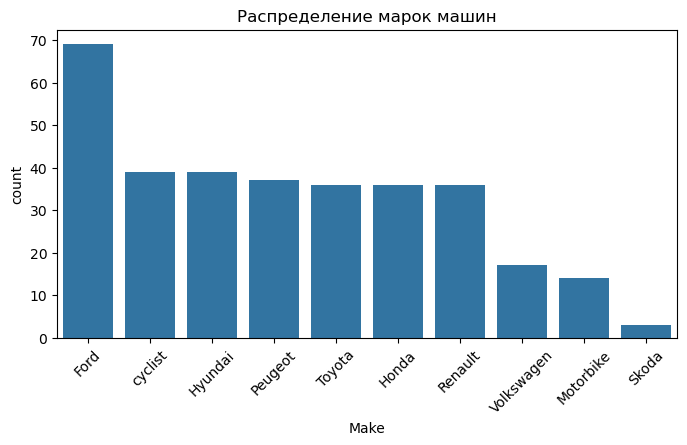

In [55]:
#Выясним самую популярную марку машины
most_popular = full_data['Make'].value_counts().idxmax()
print(f"Самая популярная марка машины: {most_popular}")

plt.figure(figsize=(8,4))
sns.countplot(data = full_data, x='Make', order = full_data['Make'].value_counts().index)
plt.title('Распределение марок машин')
plt.xticks(rotation=45)
plt.show()

Модель машины с наибольшей вместимостью: Focus


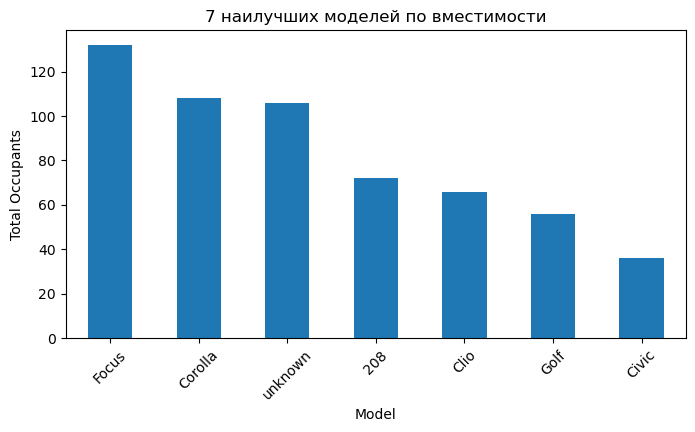

In [70]:
#У какой модели машины наибольшая вместительность(считаем сумму среди всех машин)
oc_max = full_data.groupby('Model')['Occupants'].sum().sort_values(ascending = False)
print(f"Модель машины с наибольшей вместимостью: {oc_max.idxmax()}")
plt.figure(figsize=(8,4))
oc_max.head(7).plot(kind = 'bar')
plt.ylabel('Total Occupants')
plt.xlabel('Model')
plt.xticks(rotation=45)
plt.title('7 наилучших моделей по вместимости')
plt.show()

In [87]:
#Выясним в какой день было больше всего машин
full_data['Date'] = pd.to_datetime(full_data['Date'], errors='coerce')
days_sort = full_data['Date'].dt.date.value_counts().sort_index()
days_sort
#Видим что таких дней было несколько

Date
2023-03-15    3
2023-03-16    3
2023-03-17    3
2023-03-18    3
2023-03-19    1
2023-03-20    3
2023-03-21    3
2023-03-22    3
2023-03-23    1
2023-03-24    3
2023-03-25    1
2023-03-26    3
2023-03-27    3
2023-03-28    3
2023-03-29    1
2023-03-30    3
2023-03-31    3
2023-04-01    3
2023-04-02    1
2023-04-03    3
2023-04-04    3
2023-04-05    3
2023-04-06    1
2023-04-07    3
2023-04-08    3
2023-04-09    3
2023-04-10    1
2023-04-11    3
2023-04-12    3
2023-04-13    3
2023-04-14    1
2023-04-15    3
2023-04-16    3
2023-04-17    3
2023-04-18    1
2023-04-19    3
2023-04-20    3
2023-04-21    3
2023-04-22    1
2023-04-23    3
2023-04-24    3
2023-04-25    3
2023-04-26    1
2023-04-27    3
2023-04-28    3
2023-04-29    3
2023-04-30    1
2023-05-01    3
2023-05-02    3
Name: count, dtype: int64

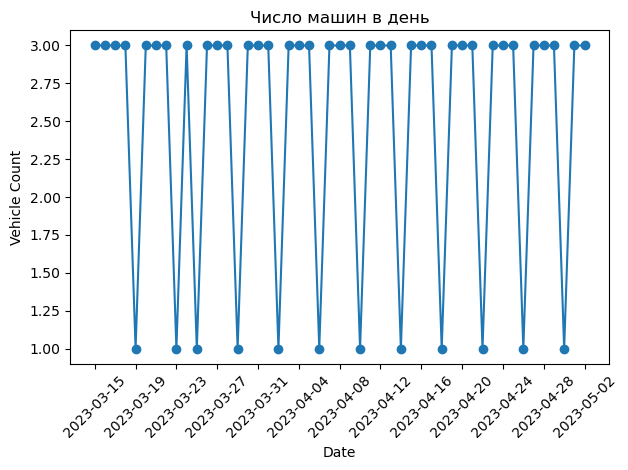

In [91]:
#Смоделируем количество траффика в каждый день
plt.plot(days_sort.index, days_sort.values, marker='o')
plt.title('Число машин в день')
plt.ylabel('Vehicle Count')
plt.xlabel('Date')
# Будем показывать только n-у дату для уменьшения визуального шума на графике
N = max(1, len(days_sort)//10)
plt.xticks(days_sort.index[::N], rotation=45)
plt.tight_layout()
plt.show()

In [94]:
full_data.to_csv("cleared_data.csv", index = False)

In [98]:
#Добавим интерактивный график с помощью виджетов, который будет отражать распределение цветов для каждой марки автомобилей
import ipywidgets as widgets
from IPython.display import display
# Выпадающий список для выбор
def plot_color_distr(select_make):
    filtered = full_data[full_data['Make'] == select_make]
    plt.figure(figsize = (8,4))
    sns.countplot(data = filtered, x = 'Car Colour', order = filtered['Car Colour'].value_counts().index)
    plt.title(f'Color distribution for: {select_make}')
    plt.ylabel('count')
    plt.xlabel('Car Colour')
    plt.xticks(rotation = 45)
    plt.tight_layout()
    plt.show()
    
make_dropdown = widgets.Dropdown(
    options = sorted(full_data['Make'].unique()),
    value = sorted(full_data['Make'].unique())[0],
    description = 'Car Make',
    disabled = False)
widgets.interact(plot_color_distr, select_make = make_dropdown)

interactive(children=(Dropdown(description='Car Make', options=('Ford', 'Honda', 'Hyundai', 'Motorbike', 'Peug…

<function __main__.plot_color_distr(select_make)>